In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import seaborn as sns

In [4]:
import matplotlib.pyplot as plt

In [5]:
from sklearn.preprocessing import LabelEncoder

In [6]:
data = pd.read_csv("C:/Users/ELCOT/Downloads/flights.csv.zip")

In [9]:
print(data.head())

   id  year  month  day  dep_time  sched_dep_time  dep_delay  arr_time  \
0   0  2013      1    1     517.0             515        2.0     830.0   
1   1  2013      1    1     533.0             529        4.0     850.0   
2   2  2013      1    1     542.0             540        2.0     923.0   
3   3  2013      1    1     544.0             545       -1.0    1004.0   
4   4  2013      1    1     554.0             600       -6.0     812.0   

   sched_arr_time  arr_delay  ... flight  tailnum origin dest air_time  \
0             819       11.0  ...   1545   N14228    EWR  IAH    227.0   
1             830       20.0  ...   1714   N24211    LGA  IAH    227.0   
2             850       33.0  ...   1141   N619AA    JFK  MIA    160.0   
3            1022      -18.0  ...    725   N804JB    JFK  BQN    183.0   
4             837      -25.0  ...    461   N668DN    LGA  ATL    116.0   

   distance  hour  minute            time_hour                    name  
0      1400     5      15  2013-01-01

In [11]:
print("Shape:", data.shape)

Shape: (336776, 21)


In [12]:
print("Columns:", data.columns)

Columns: Index(['id', 'year', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay',
       'arr_time', 'sched_arr_time', 'arr_delay', 'carrier', 'flight',
       'tailnum', 'origin', 'dest', 'air_time', 'distance', 'hour', 'minute',
       'time_hour', 'name'],
      dtype='str')


In [13]:
print("Data Types:")
print(data.dtypes)


Data Types:
id                  int64
year                int64
month               int64
day                 int64
dep_time          float64
sched_dep_time      int64
dep_delay         float64
arr_time          float64
sched_arr_time      int64
arr_delay         float64
carrier               str
flight              int64
tailnum               str
origin                str
dest                  str
air_time          float64
distance            int64
hour                int64
minute              int64
time_hour             str
name                  str
dtype: object


In [14]:
print("Missing Values:")
print(data.isnull().sum())



Missing Values:
id                   0
year                 0
month                0
day                  0
dep_time          8255
sched_dep_time       0
dep_delay         8255
arr_time          8713
sched_arr_time       0
arr_delay         9430
carrier              0
flight               0
tailnum           2512
origin               0
dest                 0
air_time          9430
distance             0
hour                 0
minute               0
time_hour            0
name                 0
dtype: int64


In [26]:
cat_cols = ['carrier', 'tailnum', 'origin', 'dest', 'name']

print("Categorical Columns:")
print(data[cat_cols].head())

Categorical Columns:
  carrier tailnum origin dest                    name
0      UA  N14228    EWR  IAH   United Air Lines Inc.
1      UA  N24211    LGA  IAH   United Air Lines Inc.
2      AA  N619AA    JFK  MIA  American Airlines Inc.
3      B6  N804JB    JFK  BQN         JetBlue Airways
4      DL  N668DN    LGA  ATL    Delta Air Lines Inc.


In [27]:
for col in cat_cols:
    if data[col].isnull().sum() > 0:
        data[col] = data[col].fillna(data[col].mode()[0])

print("After Handling Missing Values:")
print(data[cat_cols].isnull().sum())



After Handling Missing Values:
carrier    0
tailnum    0
origin     0
dest       0
name       0
dtype: int64


In [28]:
for col in cat_cols:
    print("\nFrequency Distribution:", col)
    print(data[col].value_counts())



Frequency Distribution: carrier
carrier
UA    58665
B6    54635
EV    54173
DL    48110
AA    32729
MQ    26397
US    20536
9E    18460
WN    12275
VX     5162
FL     3260
AS      714
F9      685
YV      601
HA      342
OO       32
Name: count, dtype: int64

Frequency Distribution: tailnum
tailnum
N725MQ    3087
N722MQ     513
N723MQ     507
N711MQ     486
N713MQ     483
          ... 
N766SK       1
N772SK       1
N776SK       1
N785SK       1
N557AS       1
Name: count, Length: 4043, dtype: int64

Frequency Distribution: origin
origin
EWR    120835
JFK    111279
LGA    104662
Name: count, dtype: int64

Frequency Distribution: dest
dest
ORD    17283
ATL    17215
LAX    16174
BOS    15508
MCO    14082
       ...  
MTJ       15
SBN       10
ANC        8
LEX        1
LGA        1
Name: count, Length: 105, dtype: int64

Frequency Distribution: name
name
United Air Lines Inc.          58665
JetBlue Airways                54635
ExpressJet Airlines Inc.       54173
Delta Air Lines Inc.     

In [29]:
for col in cat_cols:
    print("\nPercentage Distribution:", col)
    print(data[col].value_counts(normalize=True) * 100)




Percentage Distribution: carrier
carrier
UA    17.419590
B6    16.222949
EV    16.085766
DL    14.285460
AA     9.718329
MQ     7.838148
US     6.097822
9E     5.481388
WN     3.644856
VX     1.532770
FL     0.968002
AS     0.212010
F9     0.203399
YV     0.178457
HA     0.101551
OO     0.009502
Name: proportion, dtype: float64

Percentage Distribution: tailnum
tailnum
N725MQ    0.916633
N722MQ    0.152327
N723MQ    0.150545
N711MQ    0.144310
N713MQ    0.143419
            ...   
N766SK    0.000297
N772SK    0.000297
N776SK    0.000297
N785SK    0.000297
N557AS    0.000297
Name: proportion, Length: 4043, dtype: float64

Percentage Distribution: origin
origin
EWR    35.879932
JFK    33.042438
LGA    31.077630
Name: proportion, dtype: float64

Percentage Distribution: dest
dest
ORD    5.131898
ATL    5.111706
LAX    4.802599
BOS    4.604841
MCO    4.181414
         ...   
MTJ    0.004454
SBN    0.002969
ANC    0.002375
LEX    0.000297
LGA    0.000297
Name: proportion, Length: 105, dtyp

In [30]:
for col in cat_cols:
    print("\nMost Common Category:", col)
    print(data[col].mode()[0])


Most Common Category: carrier
UA

Most Common Category: tailnum
N725MQ

Most Common Category: origin
EWR

Most Common Category: dest
ORD

Most Common Category: name
United Air Lines Inc.


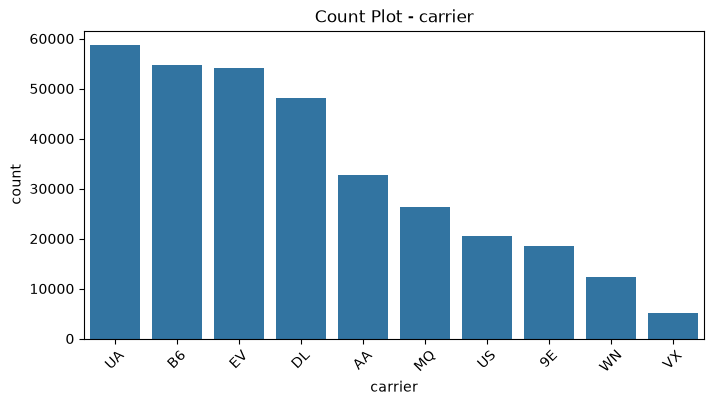

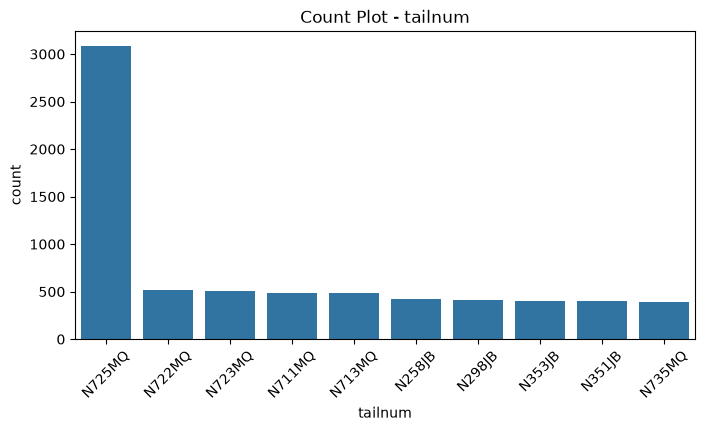

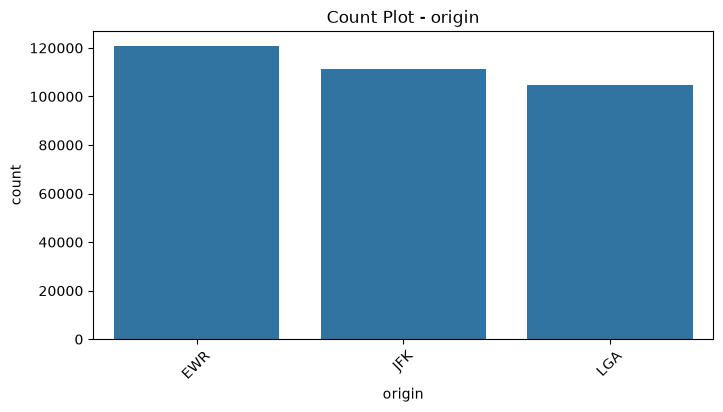

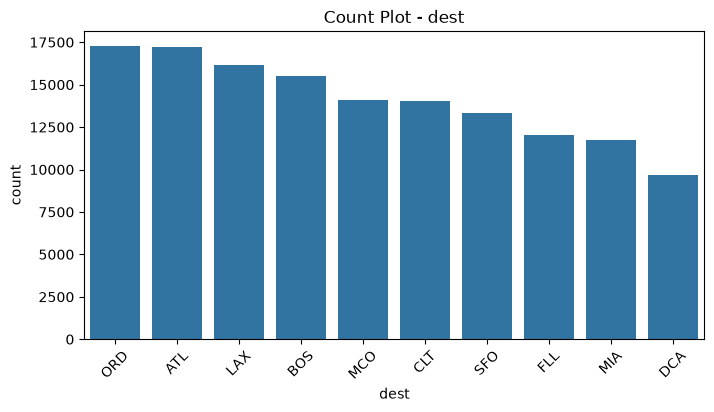

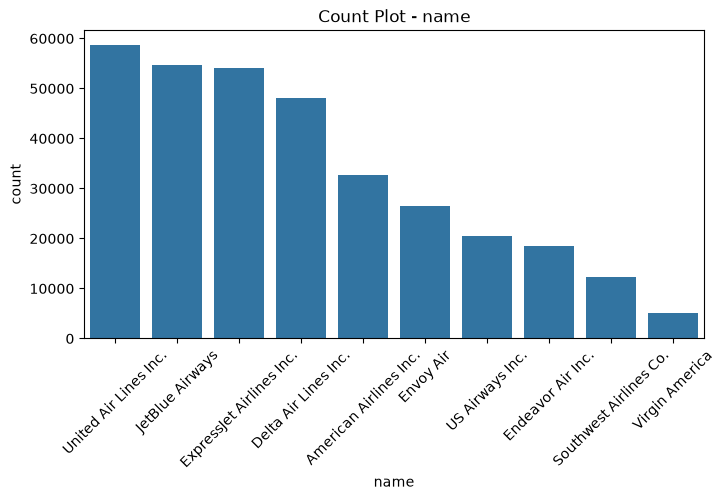

In [31]:
for col in cat_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(data=data, x=col, order=data[col].value_counts().index[:10])
    plt.title("Count Plot - " + col)
    plt.xticks(rotation=45)
    plt.show()


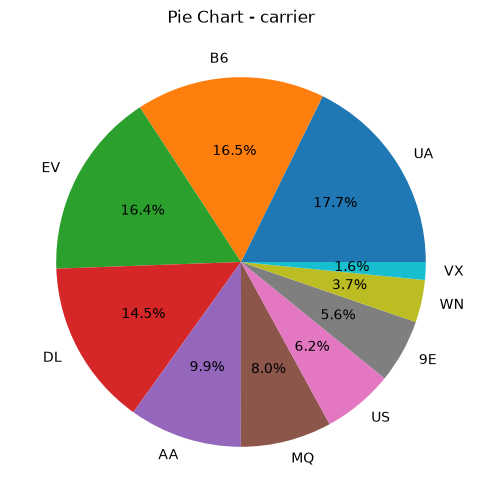

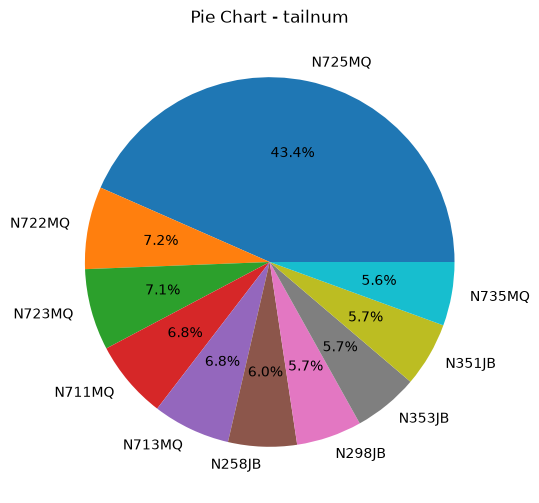

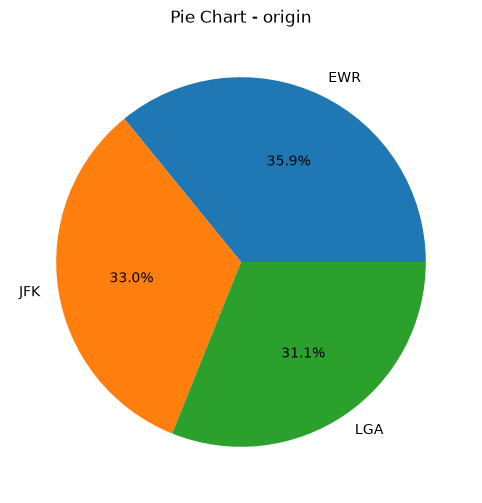

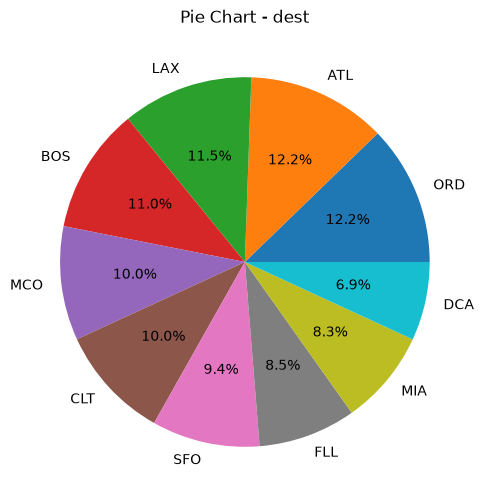

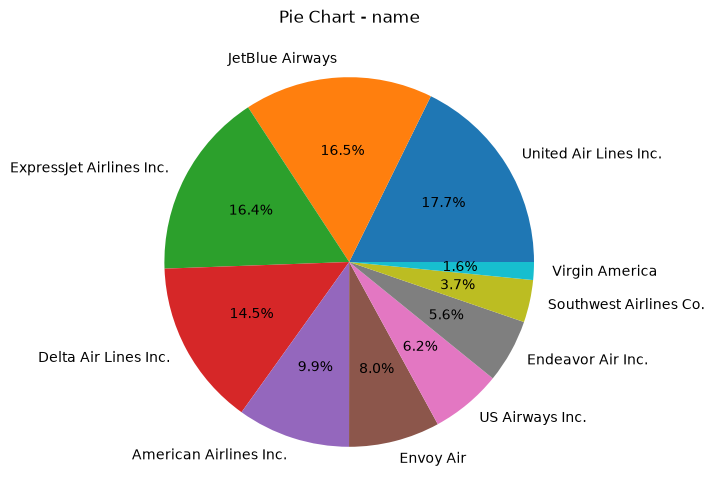

In [32]:
for col in cat_cols:
    plt.figure(figsize=(6,6))
    data[col].value_counts().head(10).plot(
        kind='pie',
        autopct='%1.1f%%'
    )
    plt.title("Pie Chart - " + col)
    plt.ylabel("")
    plt.show()

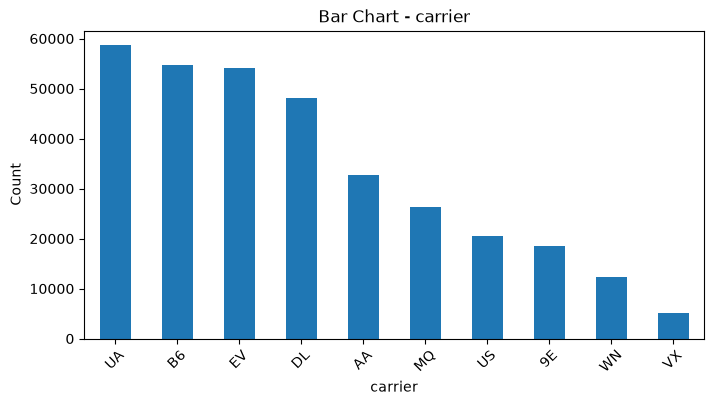

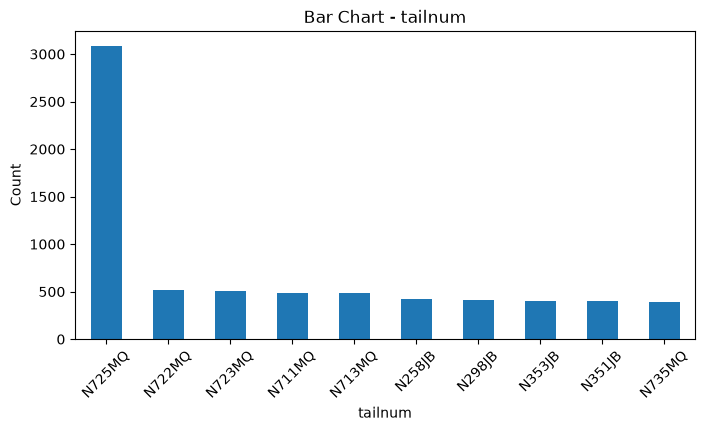

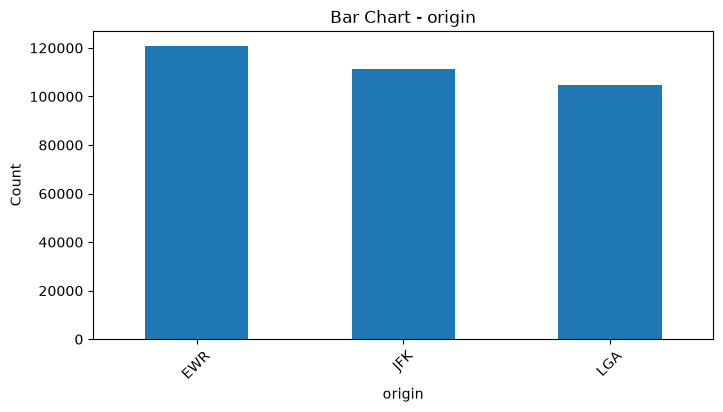

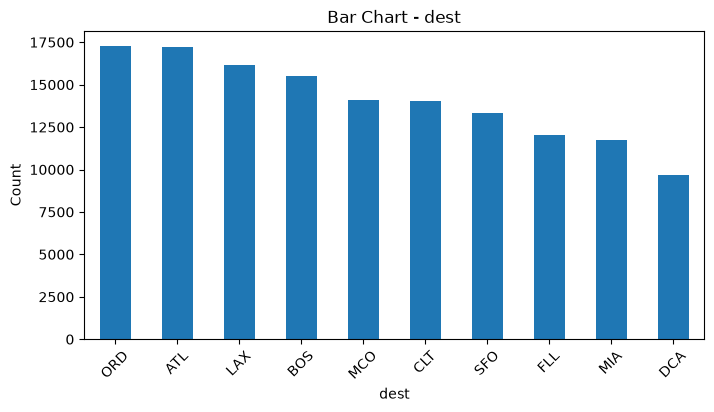

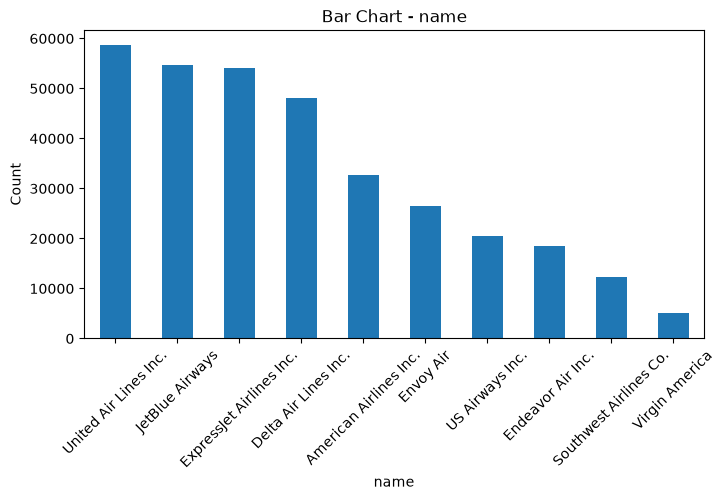

In [33]:
for col in cat_cols:
    plt.figure(figsize=(8,4))
    data[col].value_counts().head(10).plot(kind='bar')
    plt.title("Bar Chart - " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

In [36]:

encoded_data = pd.get_dummies(
    data[['carrier', 'origin']],
    dtype='int8'
)

print("Encoded Data:")
print(encoded_data.head())

print("Encoded Shape:")
print(encoded_data.shape)


MemoryError: Unable to allocate 10.1 GiB for an array with shape (336776, 4043) and data type int64

In [37]:
for col in cat_cols:
    print("\nCategory Comparison:", col)
    print(data[col].value_counts().head(10))



Category Comparison: carrier
carrier
UA    58665
B6    54635
EV    54173
DL    48110
AA    32729
MQ    26397
US    20536
9E    18460
WN    12275
VX     5162
Name: count, dtype: int64

Category Comparison: tailnum
tailnum
N725MQ    3087
N722MQ     513
N723MQ     507
N711MQ     486
N713MQ     483
N258JB     427
N298JB     407
N353JB     404
N351JB     402
N735MQ     396
Name: count, dtype: int64

Category Comparison: origin
origin
EWR    120835
JFK    111279
LGA    104662
Name: count, dtype: int64

Category Comparison: dest
dest
ORD    17283
ATL    17215
LAX    16174
BOS    15508
MCO    14082
CLT    14064
SFO    13331
FLL    12055
MIA    11728
DCA     9705
Name: count, dtype: int64

Category Comparison: name
name
United Air Lines Inc.       58665
JetBlue Airways             54635
ExpressJet Airlines Inc.    54173
Delta Air Lines Inc.        48110
American Airlines Inc.      32729
Envoy Air                   26397
US Airways Inc.             20536
Endeavor Air Inc.           18460
Southw